# pure-evo-regime (#1 / #2) *(draft digest)*

> **Status:** DRAFT in `Research/_drafts/` — approval-gated (see `Research/README.md`).

## Question

**What metaparameter regime maximizes open-ended activity under *joint* (LUT+egene) vs
*LUT-only* evolution?** And which excess metric actually tracks it?

## Method

Two mirrored pure-evolution scans, corrected excess metrics, N=256, 8000 ticks:

- **#1 `pure_evo_joint`** — LUT and egene both evolve (300 configs).
- **#2 `pure_evo_lut_only`** — egene frozen (`mu_egene = mu_egenome = tax_per_egene = 0`), 180
  configs, 0 extinct.

Axes: `mu_lut`, `m_scale`, `food_inc`. Metrics: whole-genome `excess_pc`, fixed-space
`dyn_excess_pc`, `eg_excess_pc`.

## Headline result

- **Whole-genome `excess_pc` ≈ 0 everywhere** — it does not discriminate regimes (a direct
  consequence of the scope bug documented in `neutral-model-methodology`).
- **`dyn` / `eg` excess is strongly positive** and *does* discriminate.
- The productive optimum is **low `mu_lut` + high `m_scale`** (contradicting the earlier
  broken-metric 2026-04-27 optimum of `mu_lut = 0.06`).
- **Egene-freeze *reduces* `dyn`-excess** → egene co-evolution *amplifies* rule selection; and
  the `mu_lut` optimum is **conditional on egene** (high when egene frozen, low when
  co-evolving).

In [1]:
# --- draft digest notebook: shared setup ---
# Locates the repo root (dir containing Scans/) by walking up from CWD,
# so the notebook loads raw artifacts wherever it is executed from.
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

def repo_root():
    p = Path.cwd().resolve()
    for cand in [p, *p.parents]:
        if (cand / "Scans").is_dir():
            return cand
    raise FileNotFoundError("could not locate repo root (no Scans/ dir above CWD)")

ROOT = repo_root()
print("repo root:", ROOT)


repo root: /Users/n/Projects/EvoCA/.claude/worktrees/agent-a84beb417c35593fe


In [2]:
joint = pd.read_csv(ROOT / "Scans/2026-05-17_pure_evo_joint/results.csv")
lut   = pd.read_csv(ROOT / "Scans/2026-05-17_pure_evo_lut_only/results.csv")
for name, d in [("#1 joint", joint), ("#2 lut_only", lut)]:
    print(f"{name}: {len(d)} rows, extinct={int(d.extinct.sum())}")
print()
print("whole-genome excess_pc_final  (joint): mean=%.3f  |max|=%.3f  <-- ~0, non-discriminating"
      % (joint.excess_pc_final.mean(), joint.excess_pc_final.abs().max()))
print("dyn_excess_pc_slope (joint): mean=%.2f   eg_excess_pc_slope: mean=%.2f"
      % (joint.dyn_excess_pc_slope.mean(), joint.eg_excess_pc_slope.mean()))


#1 joint: 300 rows, extinct=16
#2 lut_only: 180 rows, extinct=0

whole-genome excess_pc_final  (joint): mean=0.778  |max|=6.543  <-- ~0, non-discriminating
dyn_excess_pc_slope (joint): mean=23.01   eg_excess_pc_slope: mean=24.03


### Whole-genome excess is flat; fixed-space excess is alive

The whole-genome `excess_pc` distribution sits at ~0 across all 300 joint configs, while the
`dyn`/`eg` excess spreads widely — the fixed-space metrics carry the signal.

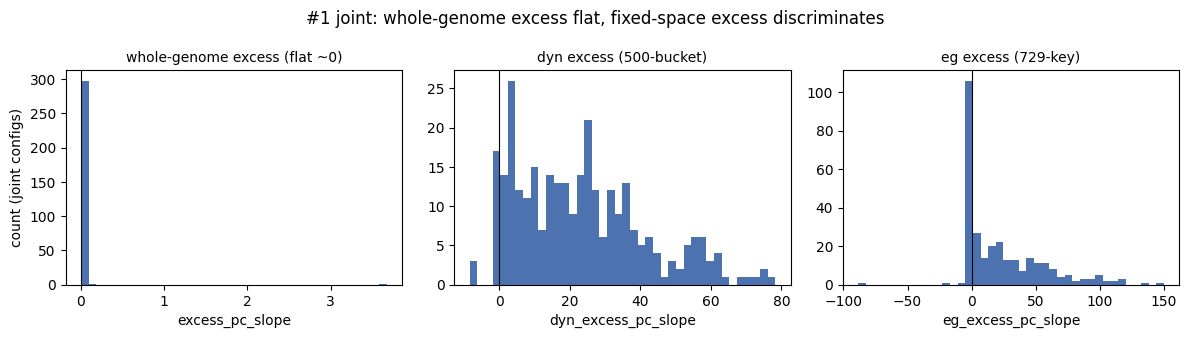

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, col, title in zip(
    axes,
    ["excess_pc_slope", "dyn_excess_pc_slope", "eg_excess_pc_slope"],
    ["whole-genome excess (flat ~0)", "dyn excess (500-bucket)", "eg excess (729-key)"],
):
    ax.hist(joint[col].dropna(), bins=40, color="#4C72B0")
    ax.axvline(0, color="k", lw=0.8)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel(col)
axes[0].set_ylabel("count (joint configs)")
fig.suptitle("#1 joint: whole-genome excess flat, fixed-space excess discriminates", fontsize=12)
fig.tight_layout(); plt.show()


### The productive optimum: low `mu_lut`, high `m_scale`

`dyn_excess_pc_slope` binned over the two active levers. (R1 later shows the `mu_lut` optimum
is *conditional* on `m_scale` — see the `viability-brackets` draft.)

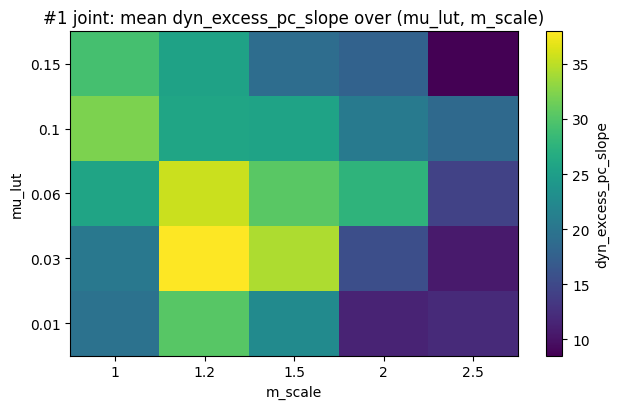

In [4]:
piv = (joint.groupby(["param_mu_lut", "param_m_scale"])
             .dyn_excess_pc_slope.mean().unstack())
fig, ax = plt.subplots(figsize=(6.5, 4.2))
im = ax.imshow(piv.values, aspect="auto", origin="lower", cmap="viridis")
ax.set_xticks(range(len(piv.columns))); ax.set_xticklabels([f"{c:g}" for c in piv.columns])
ax.set_yticks(range(len(piv.index)));   ax.set_yticklabels([f"{r:g}" for r in piv.index])
ax.set_xlabel("m_scale"); ax.set_ylabel("mu_lut")
ax.set_title("#1 joint: mean dyn_excess_pc_slope over (mu_lut, m_scale)")
fig.colorbar(im, ax=ax, label="dyn_excess_pc_slope")
fig.tight_layout(); plt.show()


### Egene-freeze reduces `dyn`-excess (egene co-evolution amplifies rule selection)

Comparing #1 (joint) vs #2 (LUT-only, egene frozen) at matched `mu_lut`: freezing the egene
lowers the *rule*-channel excess, i.e. the two channels reinforce each other. The `eg` excess
in the LUT-only scan is ≈ 0 by construction (egene frozen) — a built-in null.

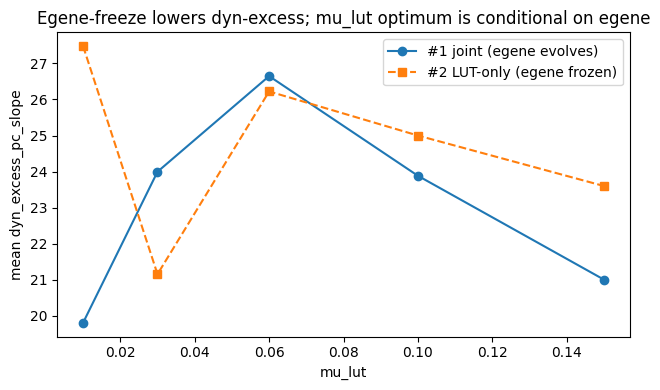

LUT-only eg_excess_pc_final mean (should be ~0, egene frozen): 0.0


In [5]:
def by_mulut(d):
    return d.groupby("param_mu_lut").dyn_excess_pc_slope.mean()
j = by_mulut(joint); l = by_mulut(lut)
common = sorted(set(j.index) & set(l.index))
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(common, [j[k] for k in common], "o-", label="#1 joint (egene evolves)")
ax.plot(common, [l[k] for k in common], "s--", label="#2 LUT-only (egene frozen)")
ax.set_xlabel("mu_lut"); ax.set_ylabel("mean dyn_excess_pc_slope")
ax.set_title("Egene-freeze lowers dyn-excess; mu_lut optimum is conditional on egene")
ax.legend(); fig.tight_layout(); plt.show()
print("LUT-only eg_excess_pc_final mean (should be ~0, egene frozen):",
      round(lut.eg_excess_pc_final.mean(), 4))


*Sources:* `Scans/2026-05-17_pure_evo_joint/`, `Scans/2026-05-17_pure_evo_lut_only/`,
`Scans/2026-05-17_pure_evo_analysis.md`, `Docs/devlog/2026-05-17_research-campaigns.md`.